# ML Kernel Roofline Analysis

Load benchmark CSV output and compare latency, throughput, estimated bandwidth, numerical error, and Roofline position. The bandwidth and arithmetic-intensity values use logical tensor traffic, not hardware counters.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('../results/measurements.csv')
df = pd.read_csv(csv_path)
df.head()

,operation,size,device,precision,median_ms,operations,gflops,logical_bytes,estimated_gb_per_s,arithmetic_intensity,max_abs_error
0,matmul,128,cpu,fp32,0.006250,4194304,671.077280,196608,31.456748,21.333333,0.000000
1,matmul,128,mps,fp32,0.324479,4194304,12.926279,196608,0.605919,21.333333,0.000000
2,matmul,128,cpu,fp16,0.628605,4194304,6.672405,98304,0.156384,42.666667,0.026066
3,matmul,128,mps,fp16,0.471230,4194304,8.900764,98304,0.208612,42.666667,0.026066
4,matmul,256,cpu,fp32,0.028812,33554432,1164.585998,786432,27.294984,42.666667,0.000000


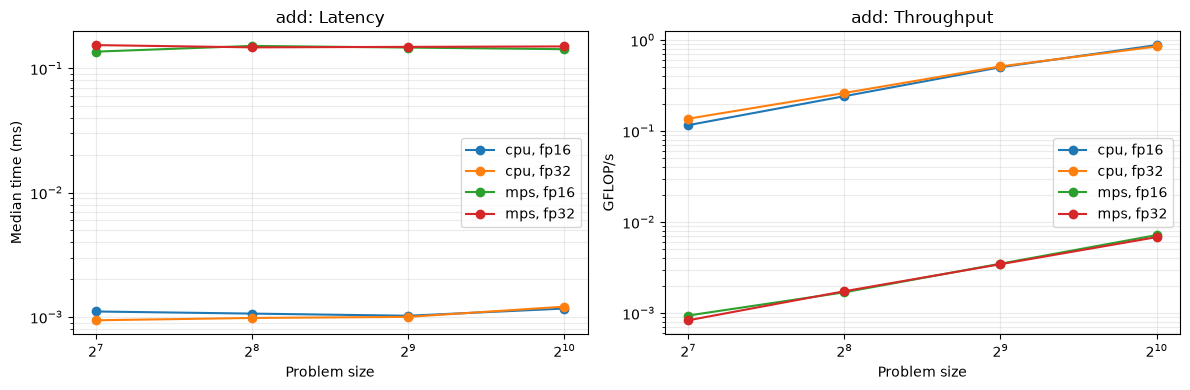

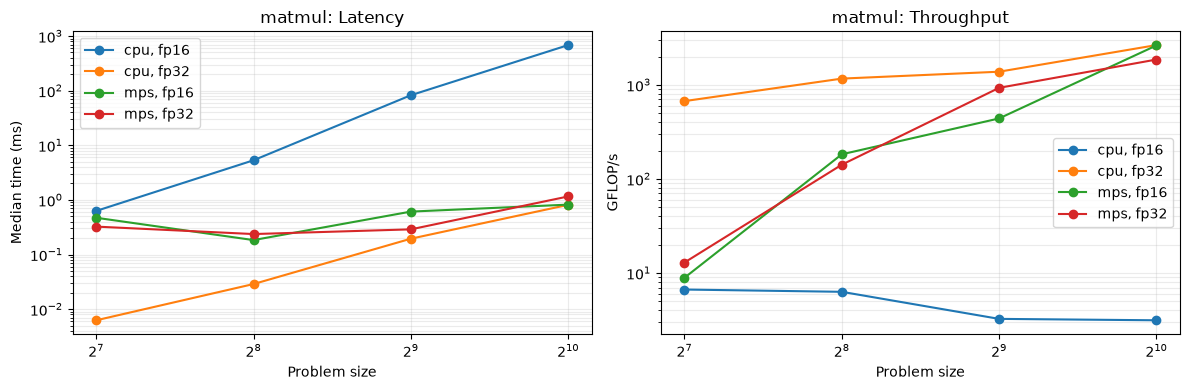

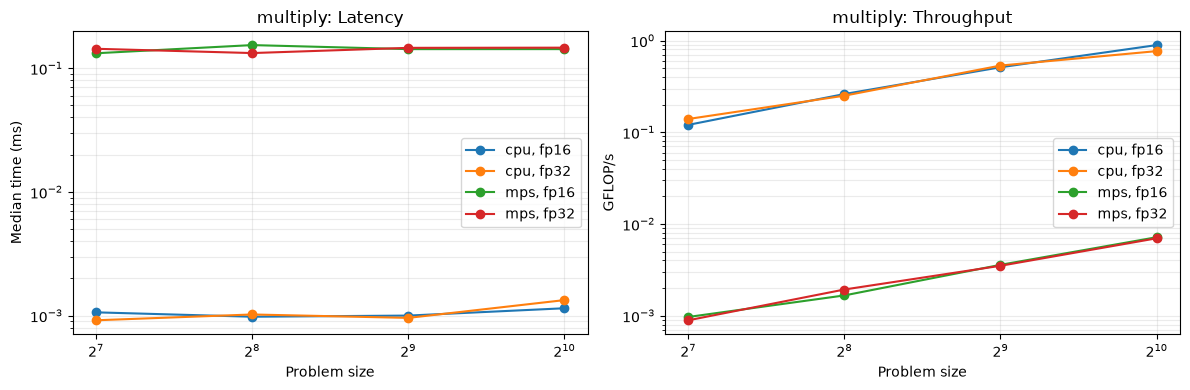

In [2]:
# Latency and throughput versus problem size. Matmul size is N for NxN @ NxN;
# elementwise size is the number of elements.
for operation, group in df.groupby('operation'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for (device, precision), series in group.groupby(['device', 'precision']):
        series = series.sort_values('size')
        label = f'{device}, {precision}'
        axes[0].plot(series['size'], series['median_ms'], marker='o', label=label)
        axes[1].plot(series['size'], series['gflops'], marker='o', label=label)
    for ax, ylabel, title in [(axes[0], 'Median time (ms)', 'Latency'),
                              (axes[1], 'GFLOP/s', 'Throughput')]:
        ax.set_xscale('log', base=2)
        ax.set_yscale('log')
        ax.set_xlabel('Problem size')
        ax.set_ylabel(ylabel)
        ax.set_title(f'{operation}: {title}')
        ax.grid(True, which='both', alpha=.25)
        ax.legend()
    plt.tight_layout()
    plt.show()

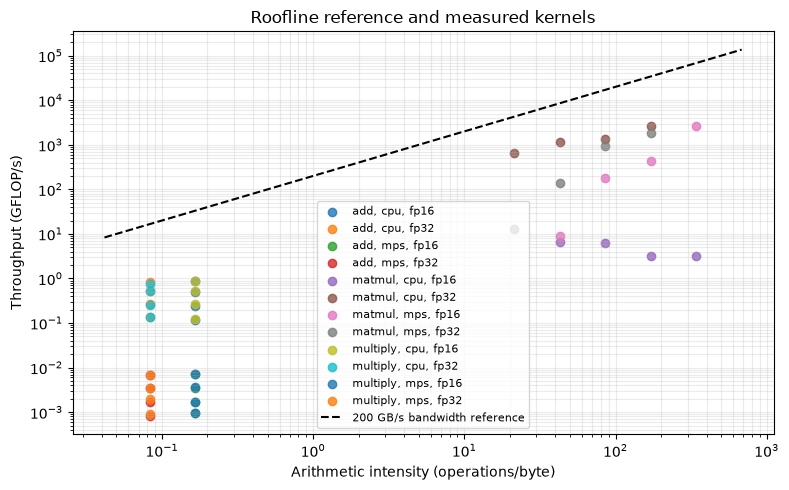

In [3]:
# A separate Roofline plot for each device and precision makes the bound
# transition visible. The default compute roof is the best GEMM throughput
# observed in this run, so it is an empirical ceiling, not a vendor peak.
# Replace an entry below with a sourced peak if a hardware-specific value is available.
MEMORY_BANDWIDTH_GB_S = 200.0  # Apple-published M2 Pro unified-memory bandwidth
COMPUTE_PEAK_OVERRIDE_GFLOPS = {
    # Example: ('mps', 'fp32'): 10000.0,
}

for (device, precision), group in df.groupby(['device', 'precision']):
    gemm = group[group['operation'] == 'matmul']
    if gemm.empty:
        print(f'Skipping {device}/{precision}: no GEMM data to set a compute roof.')
        continue
    compute_roof = COMPUTE_PEAK_OVERRIDE_GFLOPS.get(
        (device, precision), gemm['gflops'].max())
    roof_source = ('configured peak' if (device, precision) in COMPUTE_PEAK_OVERRIDE_GFLOPS
                   else 'best measured GEMM; empirical ceiling')
    knee = compute_roof / MEMORY_BANDWIDTH_GB_S
    x_min = max(group['arithmetic_intensity'].min() / 2, 1e-3)
    x_max = max(group['arithmetic_intensity'].max() * 2, knee * 10)
    xs = pd.Series(sorted({x_min, min(max(knee, x_min), x_max), x_max}))
    roof = (MEMORY_BANDWIDTH_GB_S * xs).clip(upper=compute_roof)

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(max(group['gflops'].min() / 2, 1e-3), compute_roof * 2)
    ax.axvspan(x_min, min(knee, x_max), color='cornflowerblue', alpha=.12,
               label='Memory-bound region')
    if knee < x_max:
        ax.axvspan(max(knee, x_min), x_max, color='orange', alpha=.10,
                   label='Compute-bound region')
    ax.plot(xs, roof, color='black', linewidth=2.5, label='Roofline')
    ax.plot(xs, MEMORY_BANDWIDTH_GB_S * xs, '--', color='tab:blue', alpha=.8,
            label=f'Memory roof ({MEMORY_BANDWIDTH_GB_S:g} GB/s reference)')
    ax.axhline(compute_roof, linestyle=':', color='tab:red',
               label=f'Compute roof ({compute_roof:.2f} GFLOP/s, {roof_source})')
    ax.axvline(knee, linestyle='-.', color='gray',
               label=f'Ridge point ({knee:.3g} ops/byte)')
    markers = {'matmul': 'o', 'add': 's', 'multiply': '^'}
    for operation, points in group.groupby('operation'):
        ax.scatter(points['arithmetic_intensity'], points['gflops'],
                   marker=markers.get(operation, 'o'), s=65, edgecolor='black',
                   linewidth=.4, label=operation)
    ax.text(x_min * 1.15, compute_roof * .55, 'Memory-bound\n(region)',
            color='tab:blue', weight='bold', va='center')
    if knee * 1.2 < x_max:
        ax.text(knee * 1.35, compute_roof * .55, 'Compute-bound\n(region)',
                color='darkorange', weight='bold', va='center')
    ax.set_xlabel('Arithmetic intensity (operations/byte)')
    ax.set_ylabel('Throughput (GFLOP/s)')
    ax.set_title(f'Roofline: {device.upper()} / {precision.upper()}')
    ax.grid(True, which='both', alpha=.25)
    ax.legend(fontsize=8, loc='lower right')
    plt.tight_layout()
    plt.show()

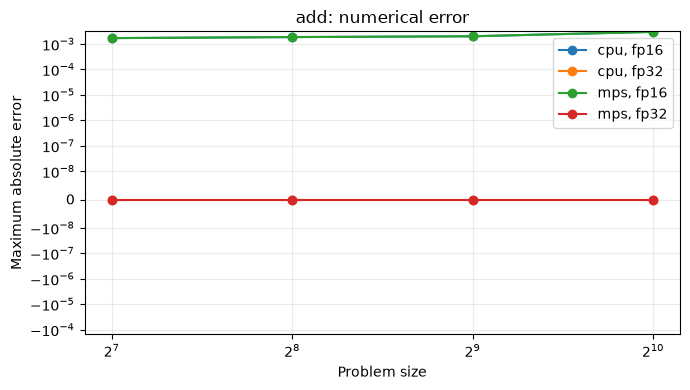

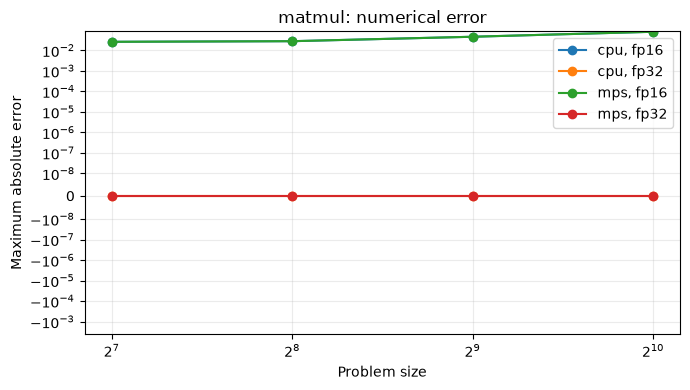

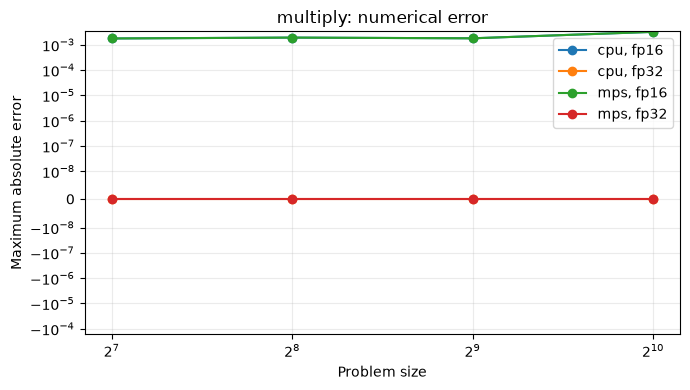

In [4]:
# Error relative to the FP32 CPU reference.
for operation, group in df.groupby('operation'):
    fig, ax = plt.subplots(figsize=(7, 4))
    for (device, precision), series in group.groupby(['device', 'precision']):
        series = series.sort_values('size')
        ax.plot(series['size'], series['max_abs_error'], marker='o',
                label=f'{device}, {precision}')
    ax.set_xscale('log', base=2)
    ax.set_yscale('symlog', linthresh=1e-8)
    ax.set_xlabel('Problem size')
    ax.set_ylabel('Maximum absolute error')
    ax.set_title(f'{operation}: numerical error')
    ax.grid(True, which='both', alpha=.25)
    ax.legend()
    plt.tight_layout()
    plt.show()